# Audio-pretrained transfer | Optional extension
**Member 4 · Mahij Khantigiri Gosai**

This separate investigation uses external AudioSet pretraining and model-specific audio frontends. Scores are validation-only and not a controlled comparison of CNN architecture alone.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'reports').exists():
    ROOT = ROOT.parent
assert (ROOT / 'reports/member4/model_comparison.csv').exists()
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
audio = pd.read_csv(ROOT/'reports/member4_audio/model_comparison.csv')
panns = pd.read_csv(ROOT/'reports/member4_panns/classifier_comparison.csv')
ast = pd.read_csv(ROOT/'reports/member4_ast/frozen_comparison.csv')
ensemble = pd.read_csv(ROOT/'reports/member4_ast/final_ensemble_comparison.csv')
print(f'{len(audio)} audio CNN runs, {len(panns)} PANNs classifier fits, {len(ast)} AST classifier fits')


16 audio CNN runs, 6 PANNs classifier fits, 18 AST classifier fits


## 1. EfficientAT: frozen and fine-tuned

,name,stage,seed,accuracy,macro_f1,total_parameters
0,mn20_as_confirm_123_1_partial,partial,123,90.196,91.017,16585250
1,mn20_as_opt_higher_lr,full,42,89.706,90.851,16585250
2,mn20_as_confirm_123_2_full,full,123,89.706,90.644,16585250
3,mn20_as_partial,partial,42,89.706,90.601,16585250
4,mn20_as_opt_mixup,full,42,89.461,90.649,16585250
5,mn10_as_partial,partial,42,89.338,90.362,4214554
6,mn10_as_full,full,42,89.338,90.357,4214554
7,mn20_as_full,full,42,89.338,90.345,16585250
8,mn20_as_confirm_2024_2_full,full,2024,89.338,90.335,16585250
9,mn20_as_confirm_2024_1_partial,partial,2024,89.216,90.014,16585250


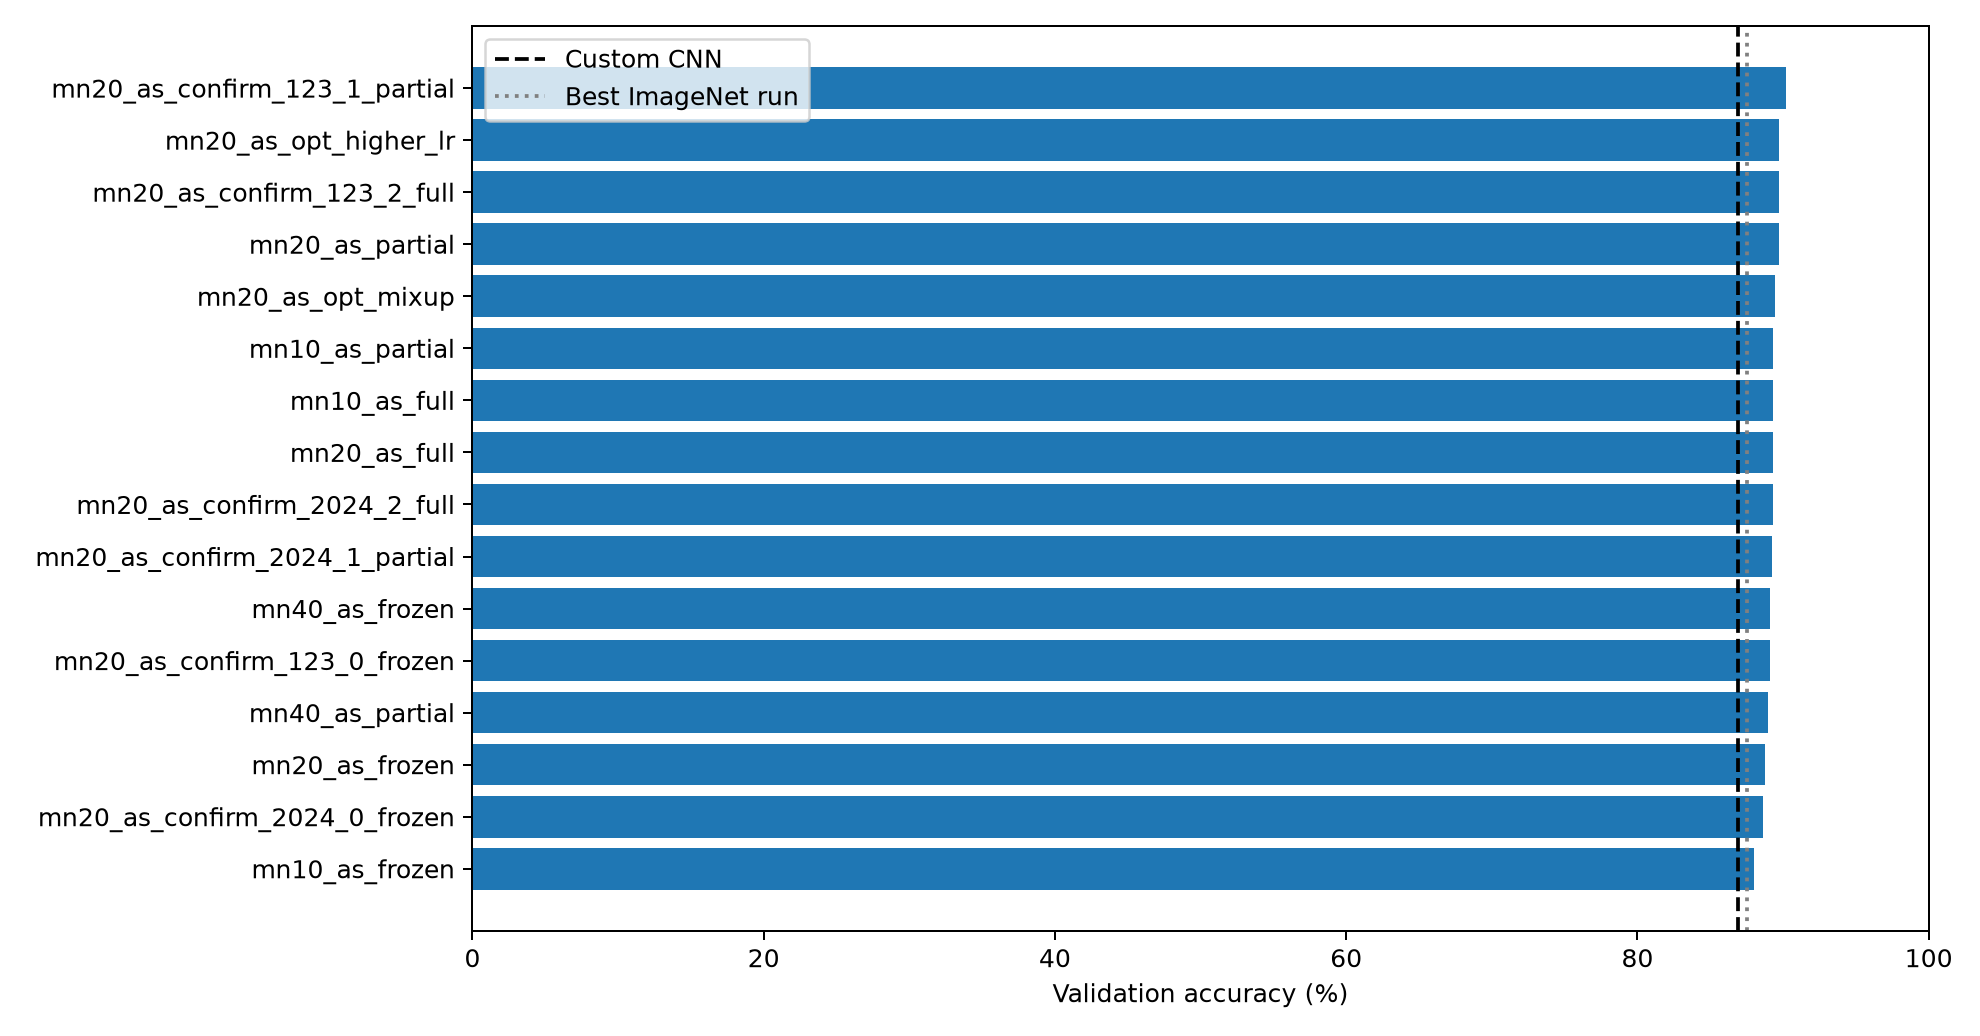

,name,seed,accuracy,macro_f1
0,mn20_as_opt_higher_lr,42,89.706,90.851
1,mn20_as_confirm_123_2_full,123,89.706,90.644
2,mn20_as_confirm_2024_2_full,2024,89.338,90.335


In [2]:
display(audio[['name','stage','seed','accuracy','macro_f1','total_parameters']].round(3))
display(Image(filename=str(ROOT/'figures/audio_transfer/comparison.png')))
display(pd.read_csv(ROOT/'reports/member4_audio/seed_comparison.csv').round(3))


## 2. Frozen PANNs and AST representations
The frozen classifiers are trained only on the training partition. AST final-block tuning is a separate optional experiment.

In [3]:
display(panns.round(3))
display(ast.head(6).round(3))
display(pd.read_csv(ROOT/'reports/member4_ast/tail_history.csv').round(3))


,name,accuracy,macro_f1,balanced_accuracy,classifier_fit_seconds
0,rbf_C1.0,88.971,90.132,90.587,3.575
1,rbf_C10.0,88.113,89.127,89.649,2.660
2,rbf_C30.0,88.113,89.280,89.872,2.599
3,logistic_C0.1,85.294,86.223,87.335,1.385
4,logistic_C1.0,85.172,86.114,87.260,2.216
5,logistic_C10.0,84.681,85.524,86.860,3.350


,name,representation,accuracy,macro_f1,balanced_accuracy,fit_seconds
0,embedding_rbf_C1.0,embedding,89.706,91.026,91.197,8.402
1,logits_rbf_C1.0,logits,89.338,90.796,91.097,4.720
2,embedding_rbf_C10.0,embedding,89.338,90.680,90.897,8.326
3,combined_rbf_C10.0,combined,89.216,90.517,90.797,9.913
4,logits_logistic_C0.1,logits,88.480,89.906,90.397,0.145
5,embedding_logistic_C0.1,embedding,88.480,89.794,90.197,0.088


,epoch,train_loss,accuracy,macro_f1,balanced_accuracy,epoch_seconds
0,1,0.462,87.990,89.387,89.797,38.659
1,2,0.418,88.603,89.957,90.297,38.226
2,3,0.395,88.480,89.818,90.197,37.857
3,4,0.379,88.603,89.872,90.297,38.140
4,5,0.369,88.603,89.886,90.297,39.624


## 3. Multi-seed and CNN/transformer ensembles

,name,accuracy,macro_f1,balanced_accuracy
0,cnn_ast_frozen_equal,90.809,91.923,92.334
1,cnn_ast_both,90.564,91.705,92.109
2,cnn_diverse_tta,90.319,91.244,91.934
3,cnn_ast_tail_equal,90.074,91.275,91.709
4,ast_frozen,89.583,90.878,91.084
5,ast_tail,88.603,89.957,90.297


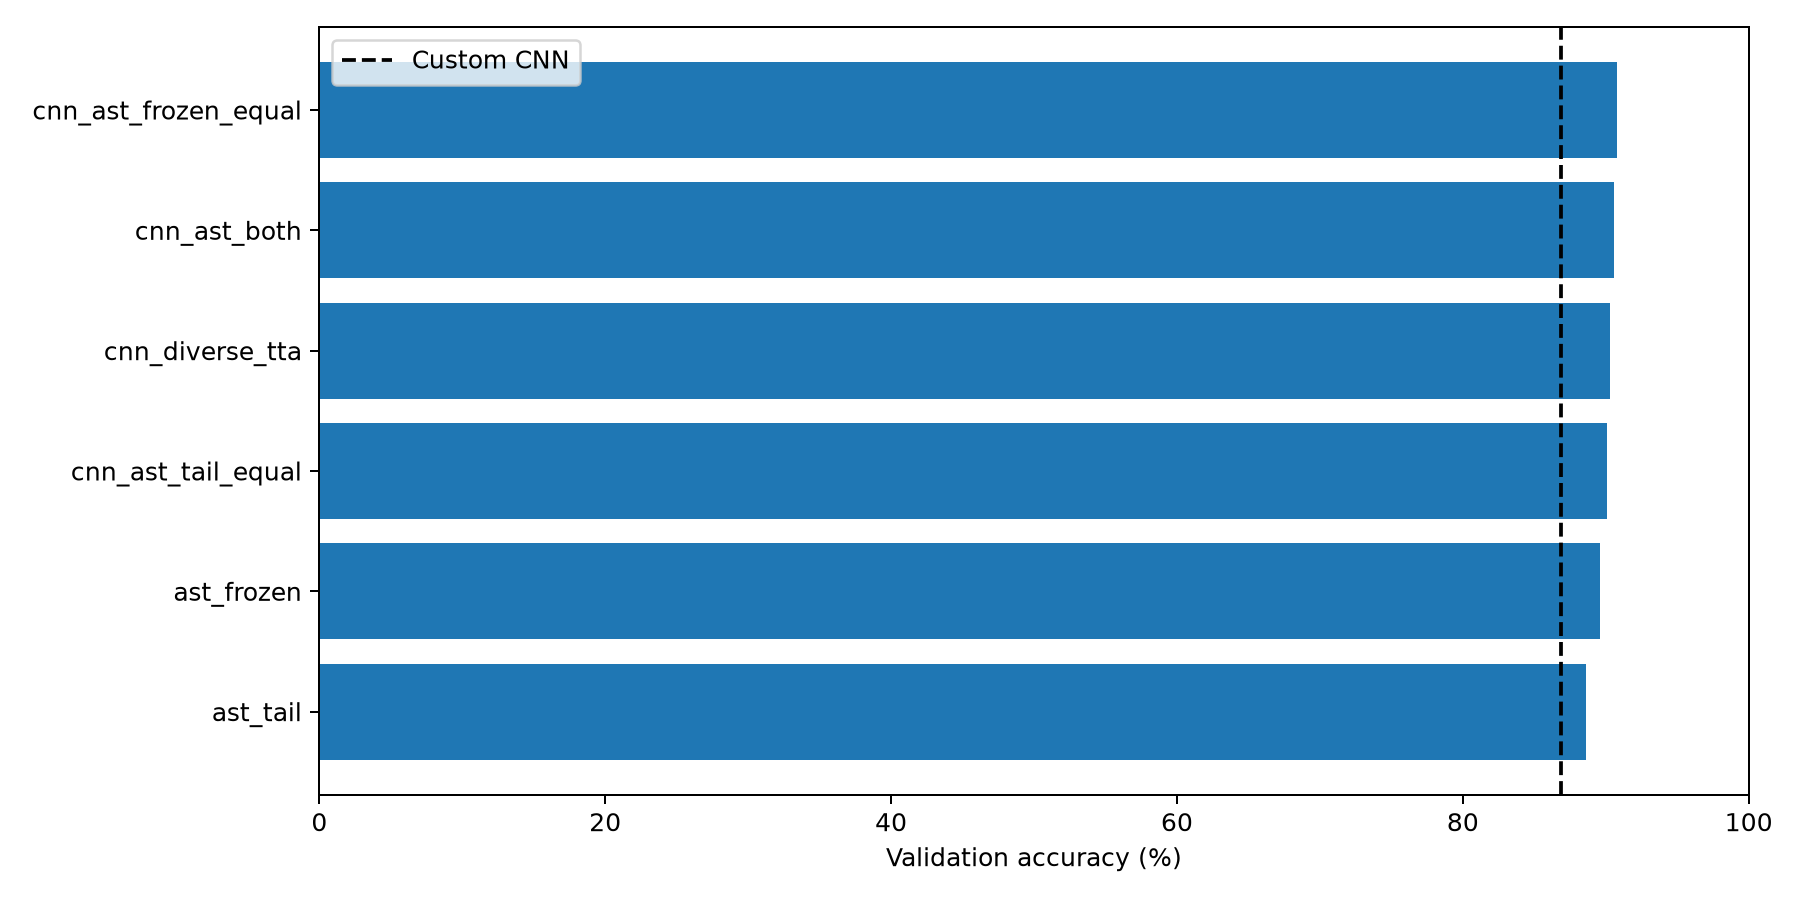

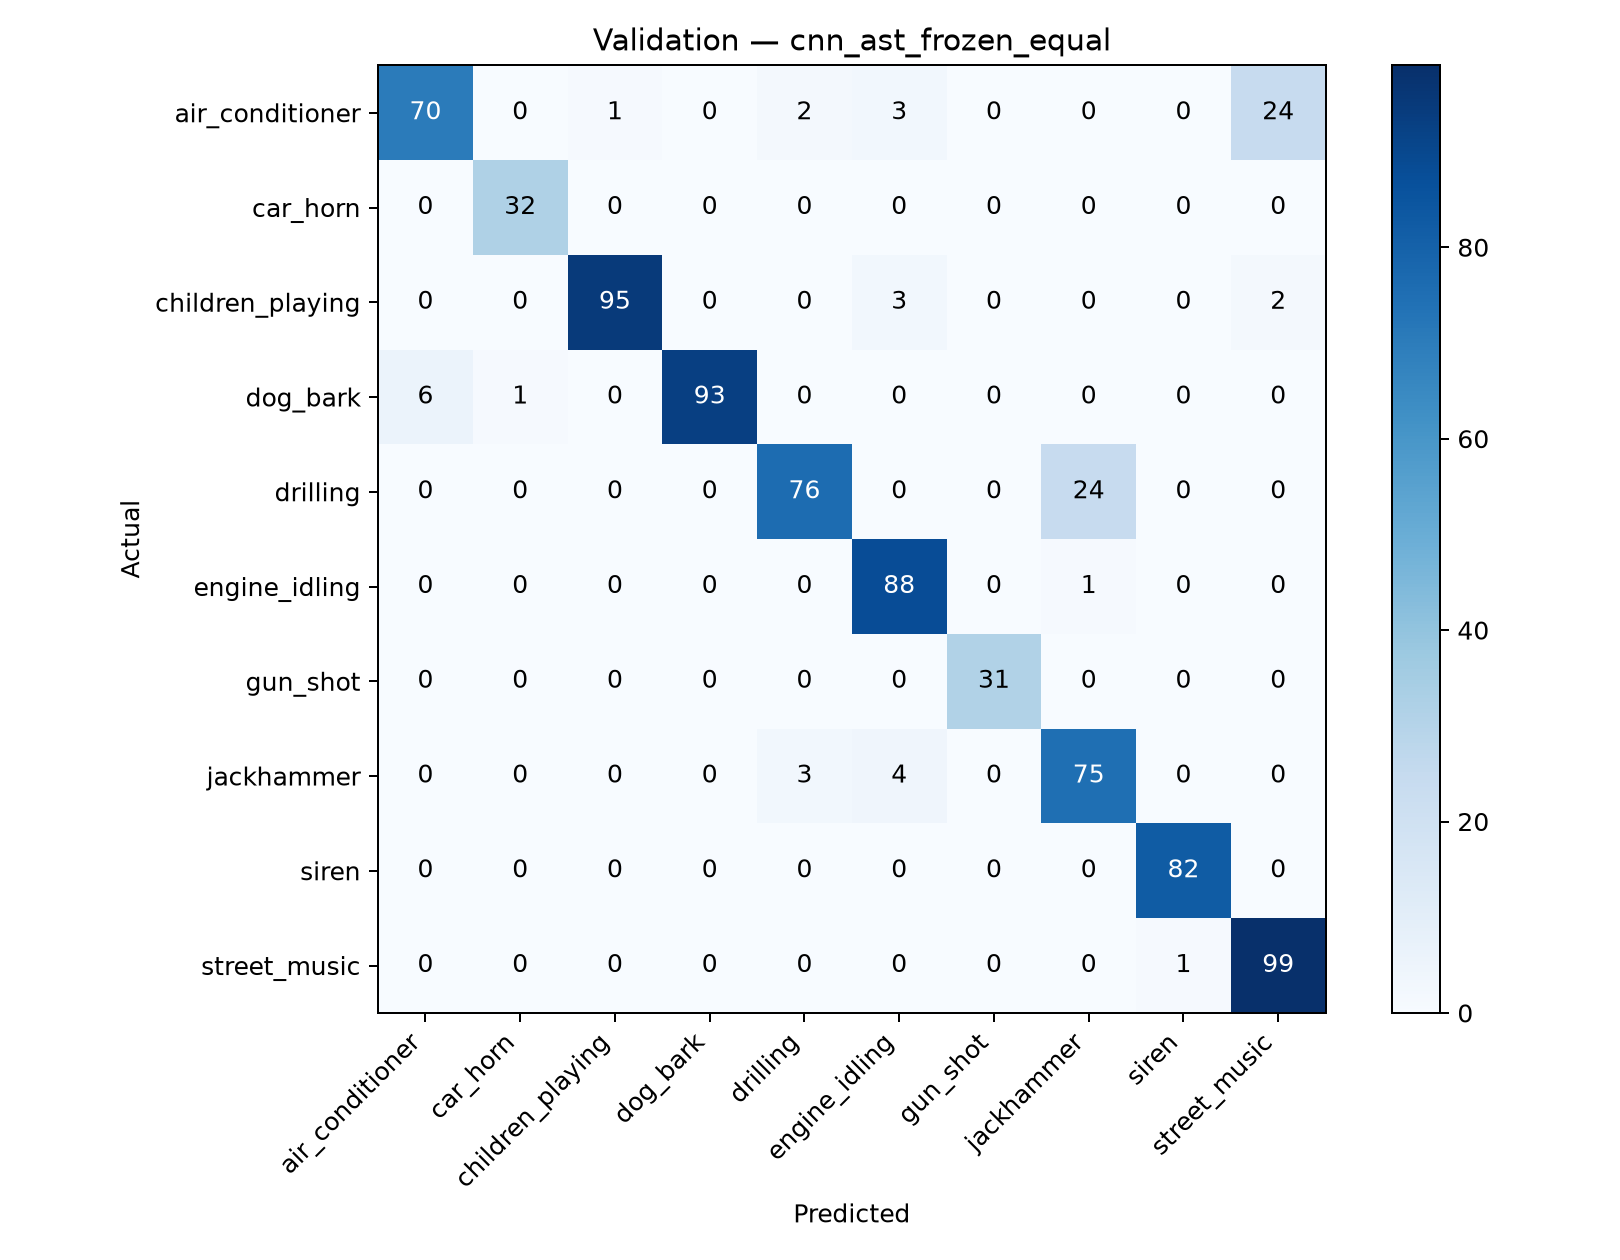

,precision,recall,f1-score,support
air_conditioner,0.921,0.700,0.795,100.000
car_horn,0.970,1.000,0.985,32.000
children_playing,0.990,0.950,0.969,100.000
dog_bark,1.000,0.930,0.964,100.000
drilling,0.938,0.760,0.840,100.000
engine_idling,0.898,0.989,0.941,89.000
gun_shot,1.000,1.000,1.000,31.000
jackhammer,0.750,0.915,0.824,82.000
siren,0.988,1.000,0.994,82.000
street_music,0.792,0.990,0.880,100.000


In [4]:
display(ensemble.round(3))
display(Image(filename=str(ROOT/'figures/audio_transfer/ast_ensemble_comparison.png')))
display(Image(filename=str(ROOT/'figures/audio_transfer/ast_selected_confusion.png')))
display(pd.read_csv(ROOT/'reports/member4_ast/selected_class_metrics.csv',index_col=0).round(3))


## Conclusion
EfficientAT MN20 achieves 90.20% as a single CNN; the best exploratory ensemble reaches 90.81% (741/816 correct). External pretraining overlap cannot be ruled out. The 95% stretch objective was not attained. No test-set metrics are reported; the original CNN contribution remains the required handoff. See [Member 4 report](../reports/member4_report.md).